# Trabajo Práctico N° 3: SVM y Random Forest

| | |
|---|---|
| **Año** | 2026 |
| **Materia** | Minería de Datos, Tecnicatura Universitaria en Inteligencia Artificial |
| **Integrantes** | Josías Calabozo · Ismael Darruiz · Sebastián Di Carlo |

**Objetivo:** recomendar un cultivo (`clase`, 10 clases) a partir de 16 parámetros de suelo y clima (`crop_recommendation_geo.csv`), con SVM de kernel lineal, SVM de kernel gaussiano (RBF) y Random Forest.

**Contenido:**

1. Preparación de datos
2. SVM con kernel lineal
3. SVM con kernel gaussiano (RBF)
4. Random Forest
5. Comparación de modelos
6. Conclusiones

Todos los modelos se evalúan con la misma validación cruzada estratificada de 5 folds sobre el conjunto limpio, con `random_state = 13`. Cuando reutilizamos código de los notebooks de clase, el comentario de la celda dice de cuál sale.

In [1]:
# Análisis exploratorio
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Preparación de los datos y validación cruzada
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Modelos
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

# random_state que pide la consigna para los modelos y la validación cruzada
SEMILLA = 13

# Ruta relativa a la carpeta del notebook (tp3/notebooks/)
RUTA_DATOS = "../data/crop_recommendation_geo.csv"

---
## 1. Preparación de datos

### 1.1 Estructura y valores faltantes

Las 16 variables predictoras, con la descripción de la consigna y las unidades de la página del dataset en Kaggle:

| Variable | Descripción | Unidad |
|---|---|---|
| `N` | Nitrógeno total en el suelo (0-30 cm) | g/kg |
| `P` | Fósforo disponible para las plantas (Olsen) | mg/kg |
| `exch_bases` | Bases intercambiables totales (Ca + Mg + K + Na), capa superficial del suelo: la medición de potasio | cmol(c)/kg |
| `ph` | pH del suelo en agua (0-30 cm) | sin unidad |
| `soc` | Carbono orgánico del suelo (0-30 cm) | g/kg |
| `arcilla` | Fracción arcillosa (0-30 cm) | % |
| `arena` | Fracción de arena (0-30 cm) | % |
| `cec` | Capacidad de intercambio catiónico | cmol(c)/kg |
| `temperatura` | Temperatura media anual del aire | °C |
| `temp_min_mensual` | Temperatura media del mes más frío | °C |
| `temp_max_mensual` | Temperatura media del mes más cálido | °C |
| `humedad` | Humedad relativa media anual | % |
| `lluvia` | Precipitación anual | mm/año |
| `estacionalidad_lluvias` | Coeficiente de variación de la precipitación mensual (BIO15) | % |
| `radiacion_solar` | Radiación solar incidente media anual | MJ/m²/día |
| `elevacion` | Altura sobre el nivel del mar | m |

In [2]:
# El archivo usa ";" como separador y coma decimal
datos = pd.read_csv(RUTA_DATOS, sep=";", decimal=",")
datos.head()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


In [3]:
# Tipo de cada columna y cantidad de valores no nulos
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

In [4]:
# Filas con algún valor faltante
datos[datos.isna().any(axis=1)]

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Hay 50004 muestras, con 16 variables predictoras numéricas y la variable objetivo `clase` como texto. Eliminamos la única fila con faltantes, la 25085 (`cafe`, sin `ph`, `cec` ni `humedad`): imputarla inventaría 3 de sus 16 valores para recuperar una fila entre más de 50.000.

### 1.2 Registros duplicados

In [5]:
# keep=False marca todas las filas que tienen una copia; duplicated() marca solo las copias de más
print(f"Filas que tienen al menos una copia: {datos.duplicated(keep=False).sum()}")
print(f"Copias de más: {datos.duplicated().sum()}")

# Cultivo de las copias
datos[datos.duplicated()]["clase"].value_counts()

Filas que tienen al menos una copia: 396
Copias de más: 198


clase
lenteja     109
manzana      55
algodon      14
garbanzo     12
maiz          3
frijol        3
arroz         2
Name: count, dtype: int64

Cada fila repetida aparece dos veces, y casi todas las copias son de `lenteja` y `manzana`. Eliminamos las 198 copias y nos quedamos con la primera aparición: si quedaran, una copia podría caer en entrenamiento y la otra en evaluación, y el modelo se evaluaría con filas que ya vio.

### 1.3 Distribución de las variables predictoras

Esperamos colas largas a la derecha en las variables del suelo (`N`, `P`, `soc`, `exch_bases` y `cec`), la lluvia y la elevación, que tienen piso pero no techo, y distribuciones más simétricas en el resto.

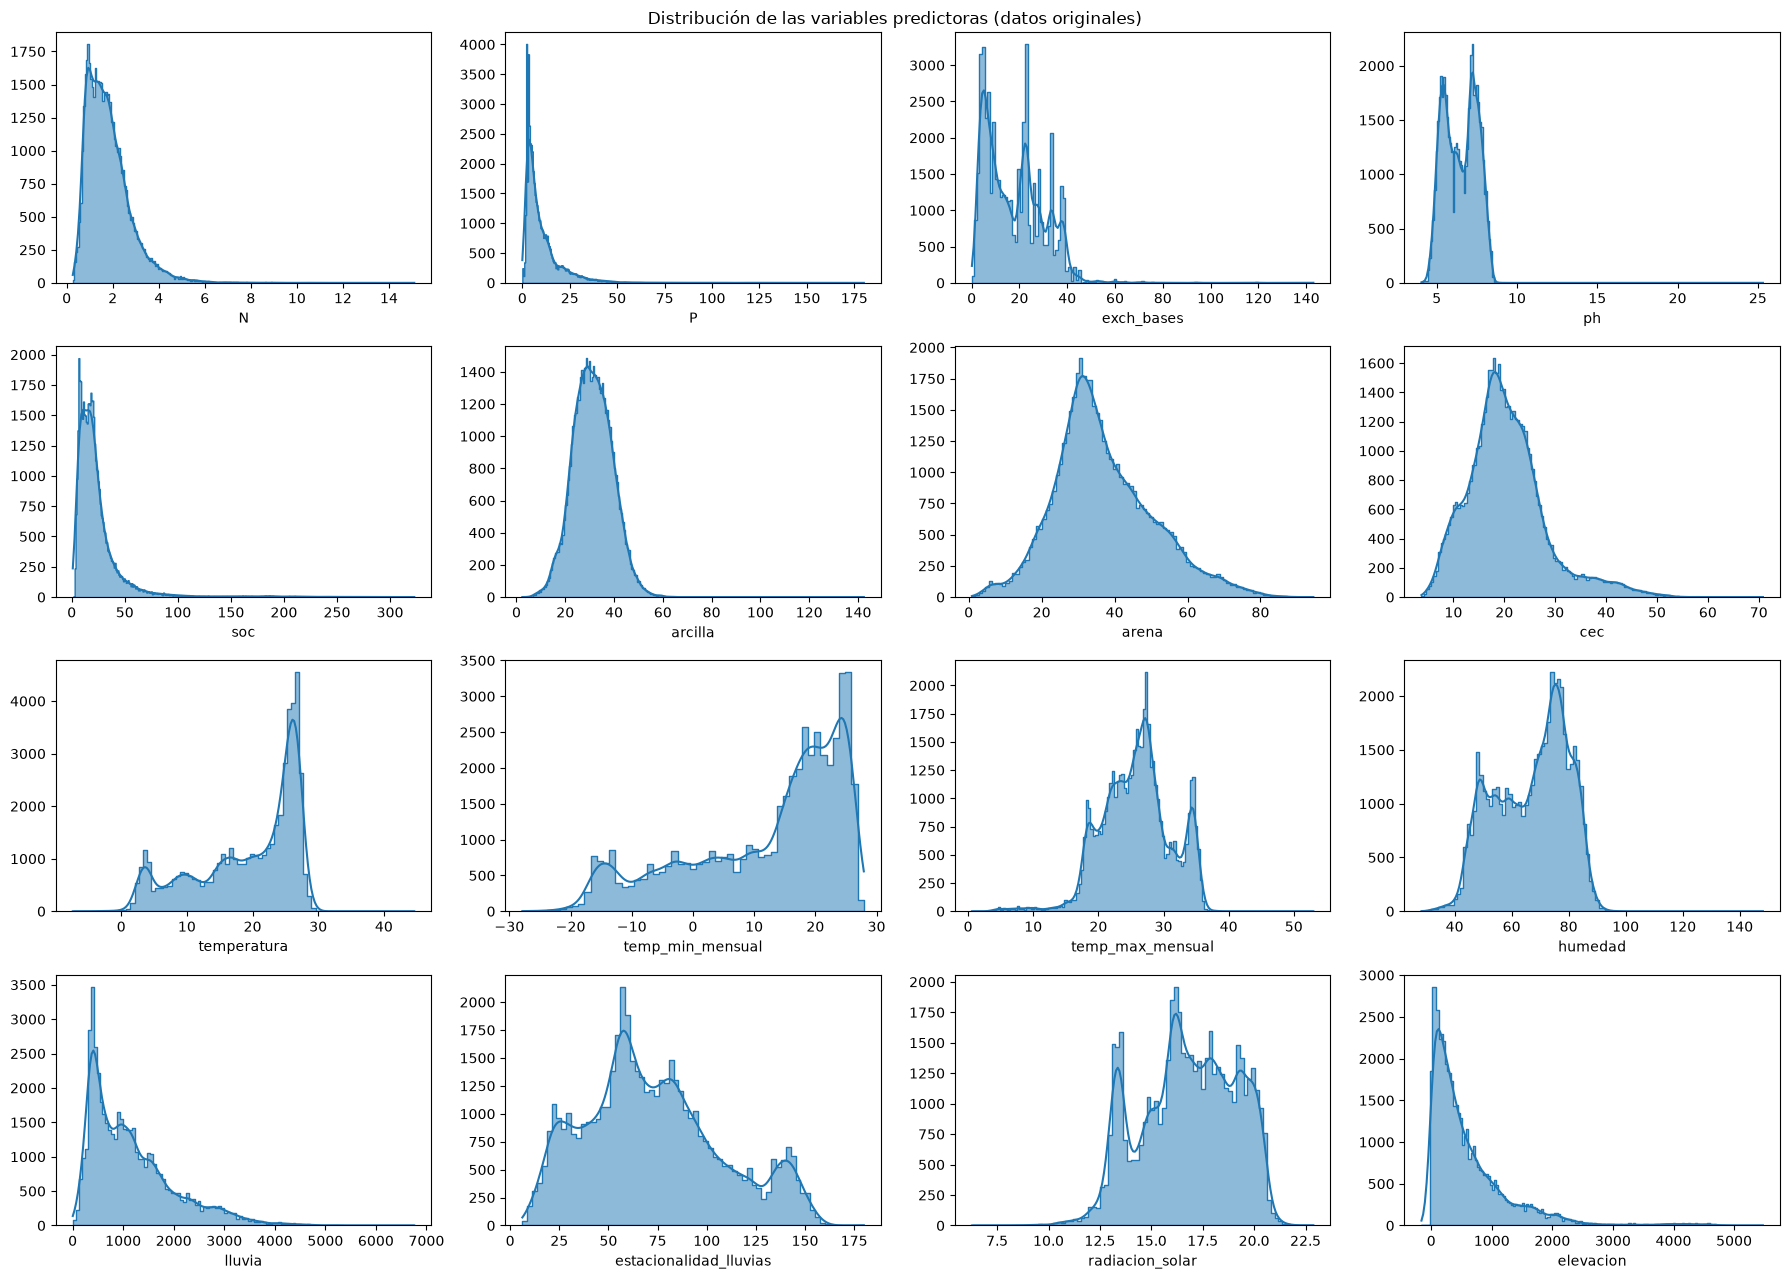

In [6]:
# Histograma de cada variable en una grilla de 4 × 4, como en U5_SVMClassifier_wine.ipynb (sección "Distribución
# de variables"), pero sin separar por clase: con 10 cultivos superpuestos no se leería
ATRIBUTOS = list(datos.columns.drop("clase"))   # las 16 variables predictoras
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, columna in zip(axes.flatten(), ATRIBUTOS):
    sns.histplot(data=datos, x=columna, kde=True, element="step", ax=ax)
    ax.set(ylabel="")
fig.suptitle("Distribución de las variables predictoras (datos originales)")
plt.tight_layout()
plt.show()

Se cumple en parte. `N`, `P`, `soc`, `lluvia` y `elevacion` tienen colas largas a la derecha, y `cec` algo menos. Pero las de rango acotado tampoco son simétricas: `ph` (cerca de 5,5 y de 7) y `humedad` tienen dos picos, y `temperatura` y `temp_min_mensual`, una cola larga hacia el frío. Esos picos pueden ser grupos de cultivos.

Además, cinco ejes se estiran mucho más allá de los datos: `ph` llega a 25 (la escala va de 0 a 14), `arcilla` y `humedad` a 142 y 148 %, y `temperatura` y `temp_max_mensual` a 44 y 53 °C. Los revisamos en 1.4.

### 1.4 Valores atípicos

Esperamos que los ejes estirados de 1.3 sean unas pocas filas con valores fuera del rango posible (el pH va de 0 a 14, y la humedad, la arcilla y la arena, de 0 a 100 %), y que la regla del rango intercuartílico marque muchos atípicos en las variables con cola larga, concentrados en algunos cultivos.

In [7]:
# Filas con valores imposibles: pH mayor a 14, o humedad relativa, arcilla o arena por encima del 100 %
fuera_de_rango = datos[(datos["ph"] > 14) | (datos["humedad"] > 100) | (datos["arcilla"] > 100)
                       | (datos["arena"] > 100)]
fuera_de_rango

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Son dos filas, y las eliminamos como errores de carga: la 25111 (`cafe`) tiene un pH de 25,3, y la 30012 (`manzana`), un pH de 18, una arcilla de 142 % y una humedad de 148 %, además de las temperaturas de 44,6 y 53 °C que estiraban los otros dos ejes. No las corregimos con la mediana: si una fila tiene un valor imposible, el resto de sus valores tampoco es confiable. Seguimos sin ellas.

In [8]:
# Función de U3_Clustering.ipynb (sección "Remocion de Outliers"), la misma que usamos en el TP1 y el TP2:
# devuelve solo las filas que quedan dentro de los límites del rango intercuartílico
def remove_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]


# Adaptada del "Conteo de atípicos por columna" de U4_DecisionTreeRegresion.ipynb, como en el TP2: cuenta con
# remove_outliers_iqr y devuelve la tabla en lugar de imprimirla. Las filas con faltantes no se cuentan
def contar_atipicos(df, columnas):
    """Cantidad y porcentaje de atípicos de cada columna, según la regla del rango intercuartílico."""
    resultados = []
    for col in columnas:
        cantidad = df[col].notna().sum() - len(remove_outliers_iqr(df, col))
        resultados.append({"Variable": col, "Cantidad": cantidad, "Porcentaje": round(100 * cantidad / len(df), 1)})
    return pd.DataFrame(resultados)


# Desde acá, sin las dos filas con valores imposibles
sin_imposibles = datos.drop(fuera_de_rango.index)
contar_atipicos(sin_imposibles, ATRIBUTOS)

,Variable,Cantidad,Porcentaje
0,N,1482,3.0
1,P,3452,6.9
2,exch_bases,181,0.4
3,ph,0,0.0
4,soc,3665,7.3
5,arcilla,294,0.6
6,arena,849,1.7
7,cec,2162,4.3
8,temperatura,13,0.0
9,temp_min_mensual,9,0.0


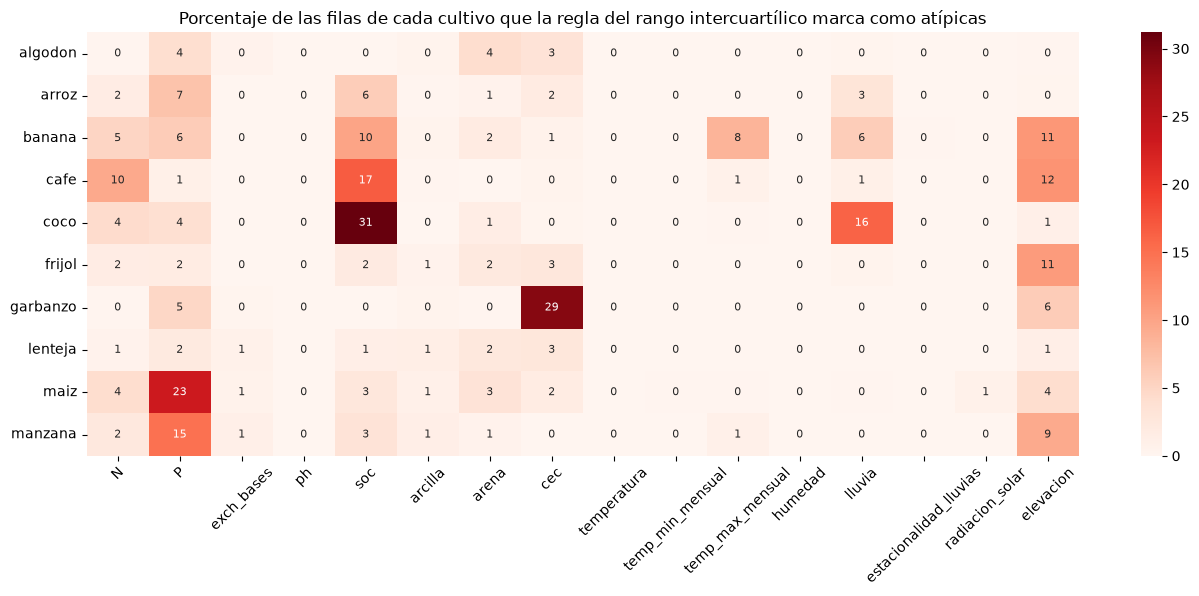

In [9]:
# De qué cultivos son los atípicos: porcentaje de las filas de cada cultivo que la regla marca en cada variable, con
# los límites de toda la columna. Mapa de calor de seaborn, como el de las correlaciones de U5_SVMClassifier_wine.ipynb
ORDEN_CLASES = sorted(datos["clase"].unique())
atipicos_por_cultivo = pd.DataFrame(index=ORDEN_CLASES)
for col in ATRIBUTOS:
    filas = sin_imposibles[sin_imposibles[col].notna()].groupby("clase").size()
    dentro = remove_outliers_iqr(sin_imposibles, col).groupby("clase").size()
    atipicos_por_cultivo[col] = 100 * (filas - dentro) / filas

plt.figure(figsize=(16, 5.5))
sns.heatmap(atipicos_por_cultivo, annot=True, fmt=".0f", cmap="Reds", annot_kws={"size": 8})
plt.title("Porcentaje de las filas de cada cultivo que la regla del rango intercuartílico marca como atípicas")
plt.xticks(rotation=45)
plt.show()

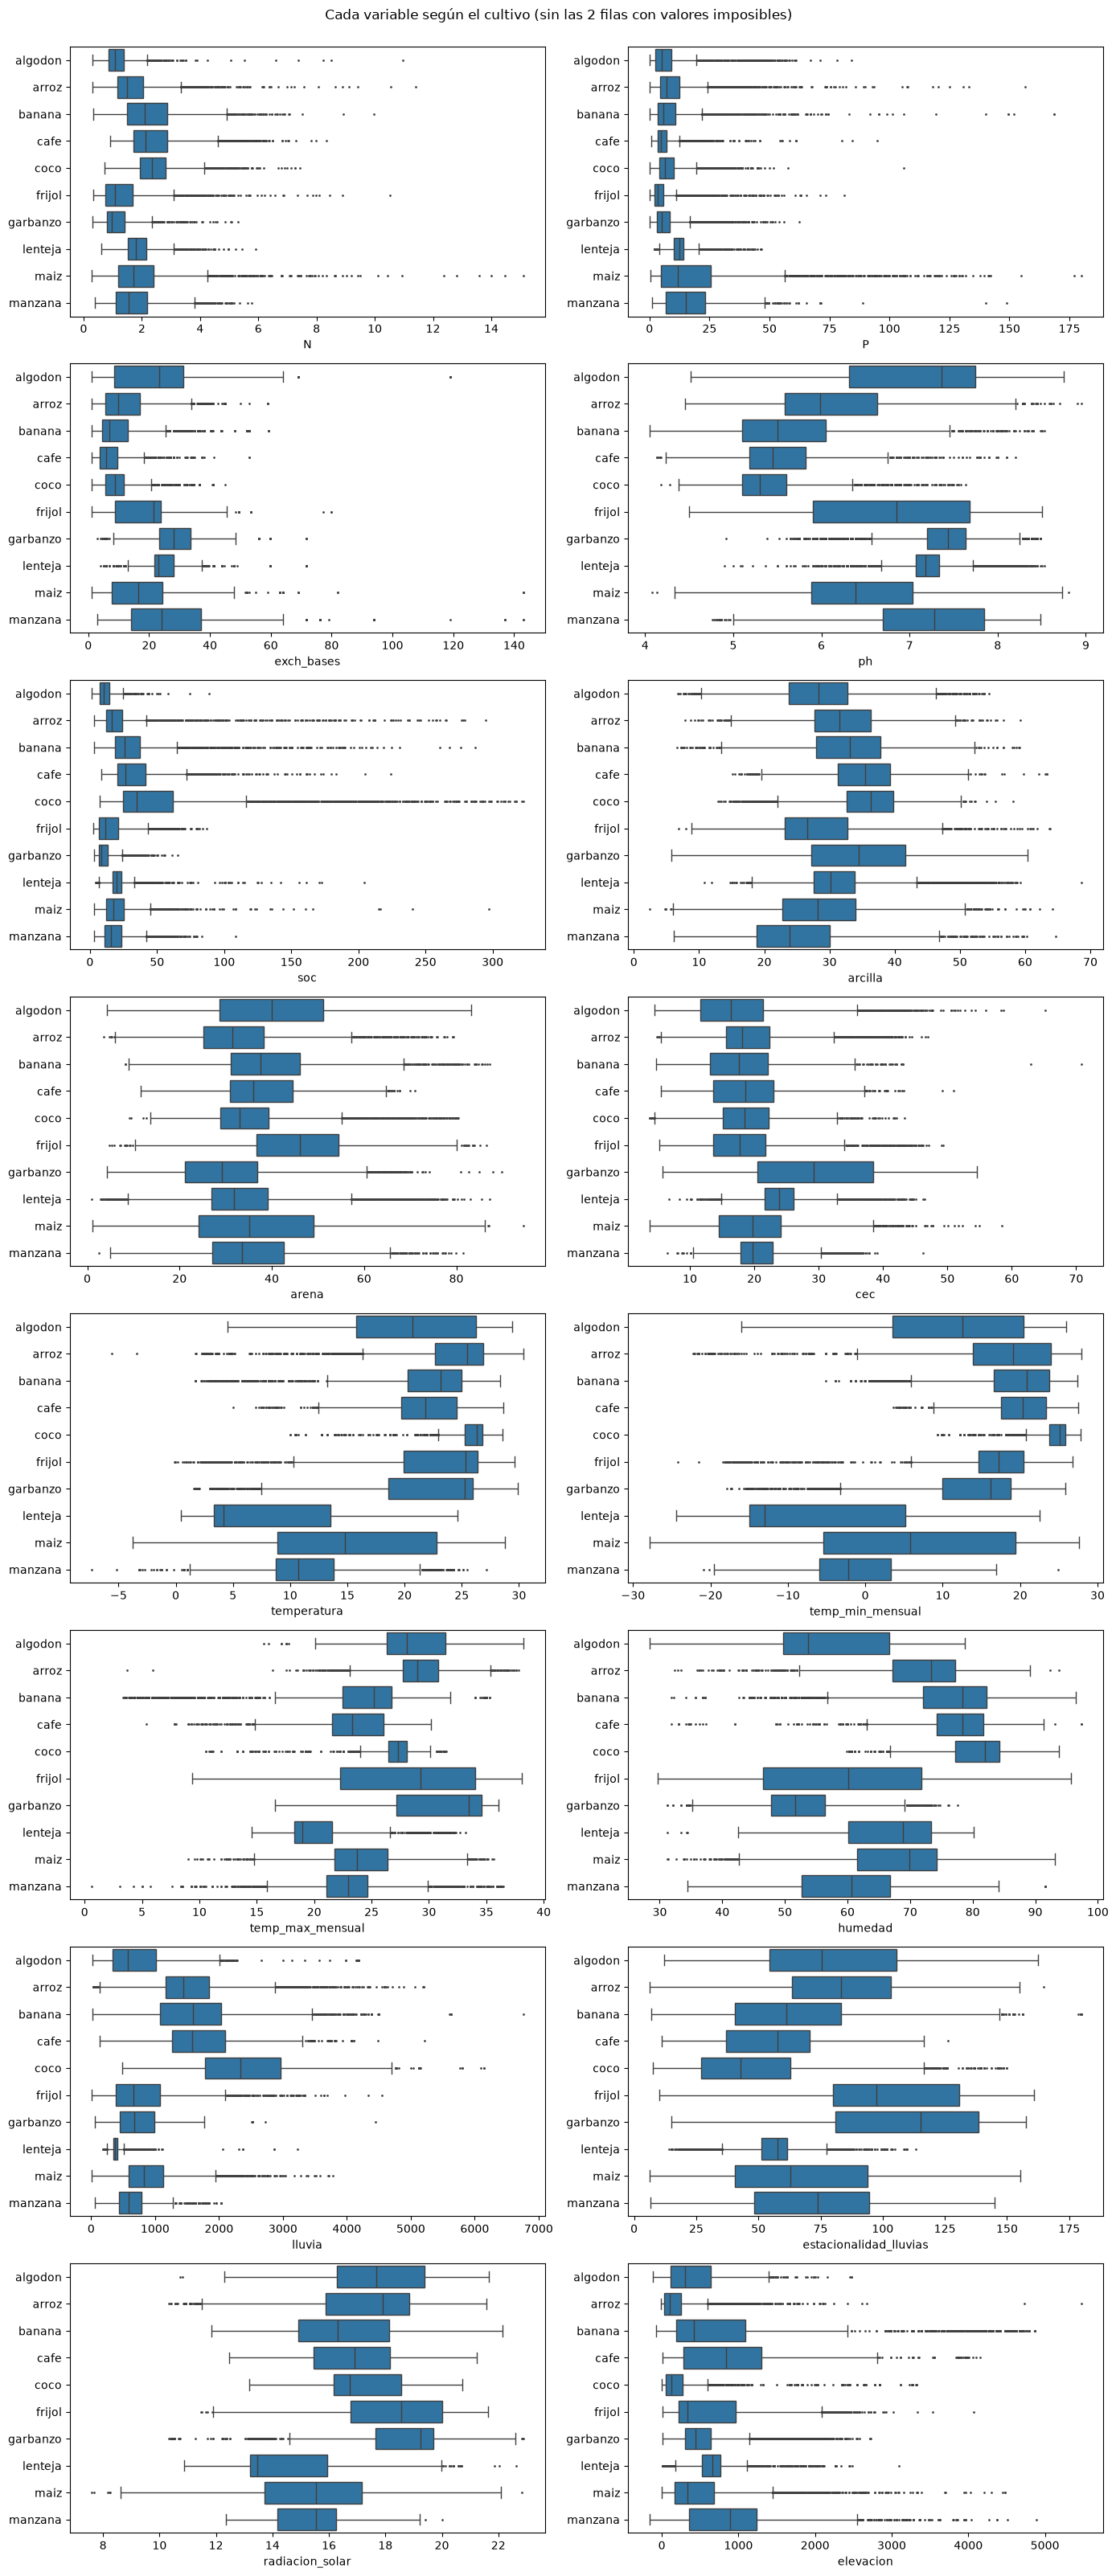

In [10]:
# Diagrama de caja de cada variable separado por cultivo, como el box plot por clase de RF_heartBinomial.ipynb (U6),
# en dos columnas para que cada panel sea más ancho
fig, axes = plt.subplots(8, 2, figsize=(14, 32))
for ax, columna in zip(axes.flatten(), ATRIBUTOS):
    sns.boxplot(data=sin_imposibles, x=columna, y="clase", order=ORDEN_CLASES, fliersize=1, ax=ax)
    ax.set(ylabel="")
fig.suptitle("Cada variable según el cultivo (sin las 2 filas con valores imposibles)", y=1.0)
plt.tight_layout()
plt.show()

Se cumple. La regla marca muchos atípicos solo en las variables con cola larga (3665 en `soc`, 3452 en `P`, 2825 en `elevacion`, 2162 en `cec`, 1482 en `N` y 1360 en `lluvia`), y el mapa muestra que se concentran en pocos cultivos: en `P`, el 23 % de las filas de `maiz` y el 15 % de las de `manzana`; en `soc`, el 31 % de `coco`; en `cec`, el 29 % de `garbanzo`, y en `elevacion`, alrededor del 11 % de `banana`, `cafe` y `frijol`. En los diagramas son colas continuas, no puntos sueltos (los de `garbanzo` en `cec` ni siquiera son atípicos dentro de su cultivo). Los conservamos: son valores posibles, y sacarlos borraría parte de lo que distingue a esos cultivos. Los dos puntos sueltos de `arroz` (bajo cero y a más de 4500 m) tampoco están fuera de rango, y es coherente que a esa altura haga frío.

Los diagramas muestran también en qué se diferencian los cultivos. Ninguna variable separa sola a los 10, pero varias separan grupos: `lenteja`, `manzana` y `maiz` son los de clima más frío y `coco` el más cálido, y `algodon`, `garbanzo`, `lenteja` y `manzana` tienen suelos neutros (pH cerca de 7), mientras que `banana`, `cafe` y `coco` los tienen ácidos (cerca de 5,5). `banana` y `cafe` se parecen en casi todas las variables, y `maiz` es el de rangos más amplios.

### 1.5 Limpieza

In [11]:
# Sacamos la fila con faltantes, las copias de las filas duplicadas y las filas con valores fuera de rango
datos_limpios = datos.dropna()
datos_limpios = datos_limpios.drop_duplicates()
datos_limpios = datos_limpios.drop(fuera_de_rango.index)
print(f"Quedan {len(datos_limpios)} de {len(datos)} filas")
datos_limpios.describe().round(2)

Quedan 49803 de 50004 filas


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
count,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00
mean,1.81,10.30,17.83,6.47,24.36,31.24,36.92,20.45,19.28,11.98,25.83,66.84,1158.18,72.89,16.78,599.35
std,0.96,11.13,11.98,1.01,26.51,8.03,13.57,7.75,7.69,12.59,5.24,12.58,833.11,34.75,2.27,660.77
min,0.26,0.00,1.00,4.05,1.02,2.40,0.88,3.72,-7.38,-27.87,0.58,28.37,3.00,6.20,7.58,-161.00
25%,1.10,3.68,7.00,5.55,11.02,25.62,28.03,15.52,14.30,3.24,22.26,56.03,486.00,48.08,15.14,158.00
50%,1.63,6.65,16.00,6.50,18.12,31.05,34.72,19.53,22.02,16.50,26.02,69.35,954.00,68.45,16.83,384.00
75%,2.27,12.84,26.50,7.35,27.23,36.77,45.07,24.20,25.79,22.12,28.99,76.98,1574.00,94.11,18.62,811.00
max,15.10,180.00,143.00,8.95,322.82,68.63,94.50,70.82,30.38,27.92,38.22,97.37,6759.00,179.91,22.88,5476.00


Quedan 49803 filas: sacamos la fila con faltantes, las 198 copias y las 2 filas con valores imposibles. Los máximos de `ph`, `arcilla`, `humedad`, `temperatura` y `temp_max_mensual` (8,95, 68,63, 97,37, 30,38 y 38,22) ya quedan en línea con el resto de cada distribución.

### 1.6 Distribución de clases

In [12]:
# Cantidad y porcentaje de muestras de cada cultivo, como target_balance de los notebooks de la U4 y la U5
pd.DataFrame({"Cantidad": datos_limpios["clase"].value_counts(),
              "Porcentaje": (datos_limpios["clase"].value_counts(normalize=True) * 100).round(2)})

,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Las clases quedan casi balanceadas, de 4891 filas (`lenteja`, 9,82 %) a 5000 (`banana`, `cafe` y `coco`, 10,04 %): es el leve desbalance que menciona la consigna. `lenteja` y `manzana`, las clases con más copias en 1.2, son las que quedan con menos filas.

### 1.7 Correlaciones

Buscamos variables que repitan la información de otra. Esperamos correlaciones fuertes entre las tres temperaturas y entre la humedad y la lluvia, y negativas entre arcilla y arena y entre la elevación y las temperaturas.

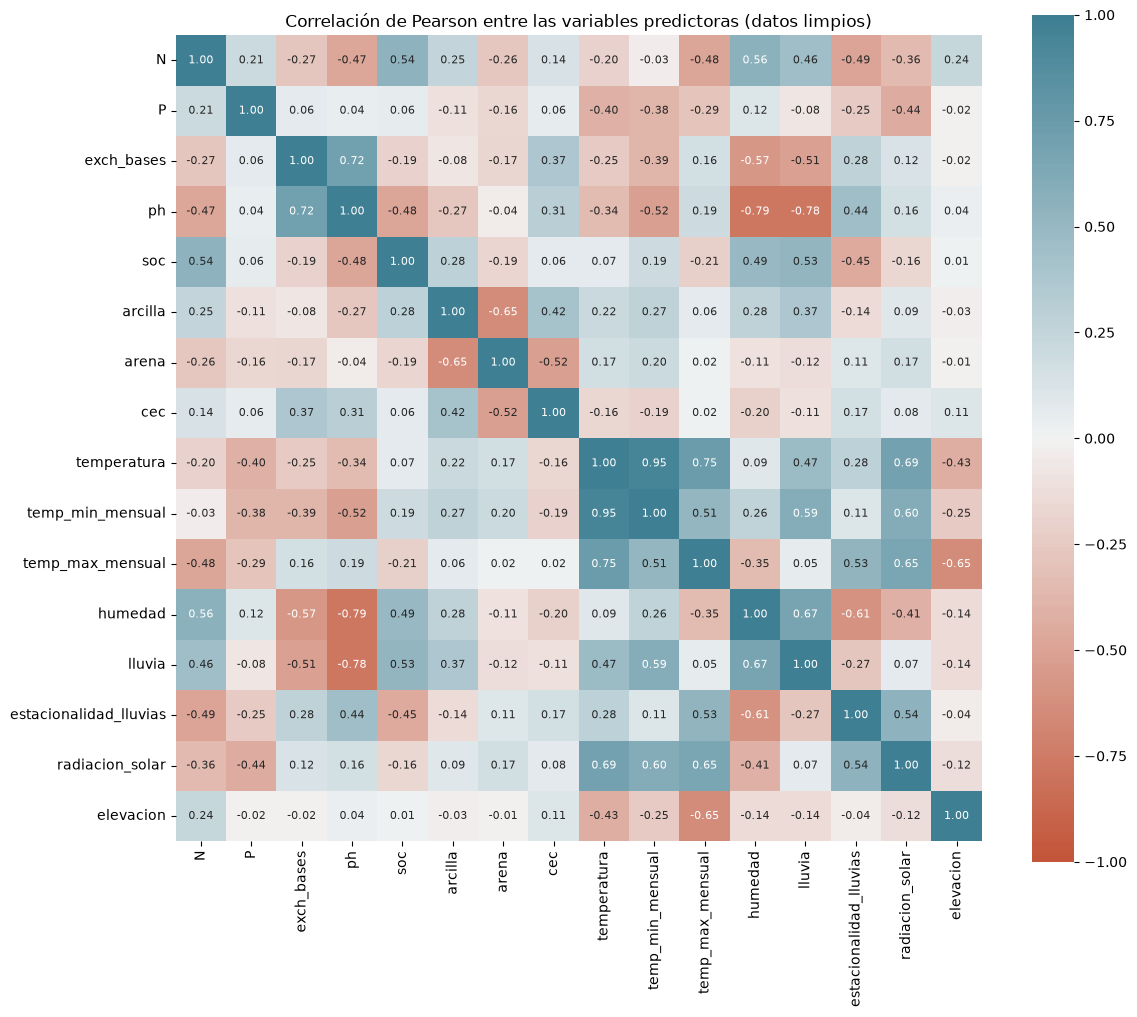

In [13]:
# Matriz de correlación de Pearson, con el mapa de calor de U5_SVMClassifier_wine.ipynb
correlaciones = datos_limpios[ATRIBUTOS].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(correlaciones, vmin=-1, vmax=1, center=0, cmap=sns.diverging_palette(20, 220, n=200),
            annot=True, fmt=".2f", annot_kws={"size": 8}, square=True)
plt.title("Correlación de Pearson entre las variables predictoras (datos limpios)")
plt.show()

Se cumple. La más alta es la de `temperatura` con `temp_min_mensual` (0,95); `humedad` y `lluvia` tienen 0,67, `arcilla` y `arena` −0,65, y la elevación −0,65 con `temp_max_mensual`. Lo que no esperábamos es que el pH baje con la humedad (−0,79) y con la lluvia (−0,78): los suelos de los lugares más lluviosos son más ácidos.

Solo `temperatura` y `temp_min_mensual` casi repiten la misma información. Igual conservamos las 16 variables que plantea la consigna.

### 1.8 Codificación, estandarización y folds

In [14]:
# LabelEncoder, como pide la consigna: cada cultivo pasa a un número de 0 a 9, en orden alfabético
codificador = LabelEncoder()
y = codificador.fit_transform(datos_limpios["clase"])
X = datos_limpios[ATRIBUTOS]
pd.DataFrame({"Cultivo": codificador.classes_}).rename_axis("Código").T

Código,0,1,2,3,4,5,6,7,8,9
Cultivo,algodon,arroz,banana,cafe,coco,frijol,garbanzo,lenteja,maiz,manzana


In [15]:
# Los 5 folds estratificados que usan todos los modelos. El archivo viene ordenado por cultivo: shuffle=True mezcla
# las filas antes de repartirlas, y es lo que hace que random_state tenga efecto
FOLDS = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Muestras de cada cultivo en cada fold
conteos = {}
for numero, (indices_train, indices_test) in enumerate(FOLDS.split(X, y), start=1):
    conteos[f"Fold {numero}"] = pd.Series(codificador.classes_[y[indices_test]]).value_counts()
conteos = pd.DataFrame(conteos)
conteos.loc["Total"] = conteos.sum()
conteos

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
algodon,997,997,997,997,998
arroz,1000,1000,1000,1000,999
banana,1000,1000,1000,1000,1000
cafe,1000,1000,1000,1000,1000
coco,1000,1000,1000,1000,1000
frijol,1000,1000,999,999,999
garbanzo,997,998,998,998,997
lenteja,978,978,979,978,978
maiz,1000,999,999,999,1000
manzana,989,989,989,989,989


Cada fold tiene 9960 o 9961 filas, con entre 978 y 1000 de cada cultivo: la estratificación mantiene las proporciones de 1.6.

In [16]:
# Cada modelo es un pipeline que estandariza y después clasifica, como el make_pipeline de Unidad4.py
def crear_modelo(clasificador):
    """Pipeline que estandariza los 16 atributos con StandardScaler y después aplica el clasificador."""
    return make_pipeline(StandardScaler(), clasificador)


# Así quedan los atributos del entrenamiento del primer fold después de estandarizar
indices_train, indices_test = next(FOLDS.split(X, y))
escalador = StandardScaler().set_output(transform="pandas")
escalador.fit_transform(X.iloc[indices_train]).describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
N,0.0,1.0,-1.58,13.82
P,0.0,1.0,-0.93,15.32
exch_bases,0.0,1.0,-1.41,10.43
ph,-0.0,1.0,-2.39,2.44
soc,0.0,1.0,-0.88,11.25
arcilla,0.0,1.0,-3.59,4.16
arena,0.0,1.0,-2.63,4.25
cec,0.0,1.0,-2.16,5.79
temperatura,0.0,1.0,-3.47,1.38
temp_min_mensual,0.0,1.0,-3.17,1.26


La estandarización va dentro de cada modelo, así el escalador se ajusta solo con los folds de entrenamiento de cada vuelta. En el fold 1 todas las variables quedan con media 0 y desvío 1, y las colas largas de 1.3 se ven en los máximos: `P` llega a 15,32 desvíos y `N` a 13,82, mientras que `ph` y `humedad` no pasan de 2,5.

---
## 2. SVM con kernel lineal

### 2.1 Búsqueda del parámetro C

Esperamos que la exactitud suba con C hasta estabilizarse, que el lineal confunda cultivos que en 1.4 se superponen en casi todas las variables, como `banana` y `cafe`, y tiempos largos, porque cada entrenamiento usa unas 40.000 filas.

Probamos 6 valores de C, de 0,001 a 100 en escala logarítmica (los 5 de la consigna y 0,001): con los 5 folds, 30 entrenamientos.

El criterio para elegir es el mismo en los tres modelos: la exactitud media en los 5 folds, que con las clases casi balanceadas (1.6) pesa a todos los cultivos casi por igual. Las combinaciones a menos de un desvío entre folds de la mejor las tomamos como equivalentes, porque esa diferencia es del tamaño de lo que cambia la exactitud de un fold a otro, y entre ellas elegimos la que entrena más rápido.

In [17]:
# Las tres métricas que pide la consigna, con promedio weighted en la precisión y la exhaustividad, como
# pd_metricas_clasifier de gas_detection.ipynb (U6)
METRICAS = {"Precisión": "precision_weighted", "Exhaustividad": "recall_weighted", "Exactitud": "accuracy"}


# GridSearchCV como en U5_SVMClassifier_wine.ipynb (sección "Optimización del modelo"), con los 5 folds de 1.8, las
# tres métricas y n_jobs=-1 para entrenar en paralelo, como en Unidad5.py. refit=False: solo evalúa, no reentrena
# la mejor combinación con todos los datos
def buscar_hiperparametros(clasificador, grilla):
    """Evalúa cada combinación de la grilla en los 5 folds y devuelve la tabla de resultados de GridSearchCV."""
    busqueda = GridSearchCV(crear_modelo(clasificador), grilla, cv=FOLDS, scoring=METRICAS, refit=False, n_jobs=-1)
    busqueda.fit(X, y)
    return pd.DataFrame(busqueda.cv_results_)


def tabla_resultados(resultados, hiperparametros):
    """Media y desvío de cada métrica en los 5 folds, y tiempo medio de entrenamiento, de cada combinación."""
    tabla = pd.DataFrame()
    for parametro, nombre in hiperparametros.items():
        tabla[nombre] = resultados[f"param_{parametro}"]
    for metrica in METRICAS:
        tabla[f"{metrica} media"] = resultados[f"mean_test_{metrica}"].round(4)
        tabla[f"{metrica} desvío"] = resultados[f"std_test_{metrica}"].round(4)
    tabla["Entrenamiento por fold (s)"] = resultados["mean_fit_time"].round(1)
    return tabla


# El criterio para elegir: las combinaciones a menos de un desvío de la mejor son equivalentes, y va la más rápida
def candidatas(resultados):
    """Combinaciones a menos de un desvío de la mayor exactitud media, de la que entrena más rápido a la más lenta."""
    mejor = resultados.loc[resultados["mean_test_Exactitud"].idxmax()]
    limite = mejor["mean_test_Exactitud"] - mejor["std_test_Exactitud"]
    return resultados[resultados["mean_test_Exactitud"] >= limite].sort_values("mean_fit_time")


def mejor_configuracion(resultados):
    """Configuración elegida: la primera de las candidatas, la que entrena más rápido."""
    return candidatas(resultados).iloc[0]

In [18]:
# En el pipeline, cada hiperparámetro lleva adelante el nombre de su paso: svc__C es el C del paso svc.
# random_state no cambia nada en un SVC (solo se usa con probability=True), pero lo fijamos como pide la consigna
GRILLA_LINEAL = {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}
resultados_lineal = buscar_hiperparametros(SVC(kernel="linear", random_state=SEMILLA), GRILLA_LINEAL)
tabla_lineal = tabla_resultados(resultados_lineal, {"svc__C": "C"})
tabla_lineal

,C,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
0,0.001,0.5670,0.0039,0.5657,0.0035,0.5657,0.0035,67.8
1,0.010,0.6048,0.0044,0.6048,0.0036,0.6048,0.0036,52.6
2,0.100,0.6172,0.0056,0.6179,0.0050,0.6179,0.0050,50.4
3,1.000,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,81.8
4,10.000,0.6230,0.0049,0.6230,0.0047,0.6230,0.0047,217.6
5,100.000,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,958.1


La exhaustividad weighted es igual a la exactitud, y lo va a ser en todos los modelos: pesar la de cada cultivo por su cantidad de filas da la proporción total de aciertos. La precisión queda muy cerca, así que en los gráficos usamos solo la exactitud.

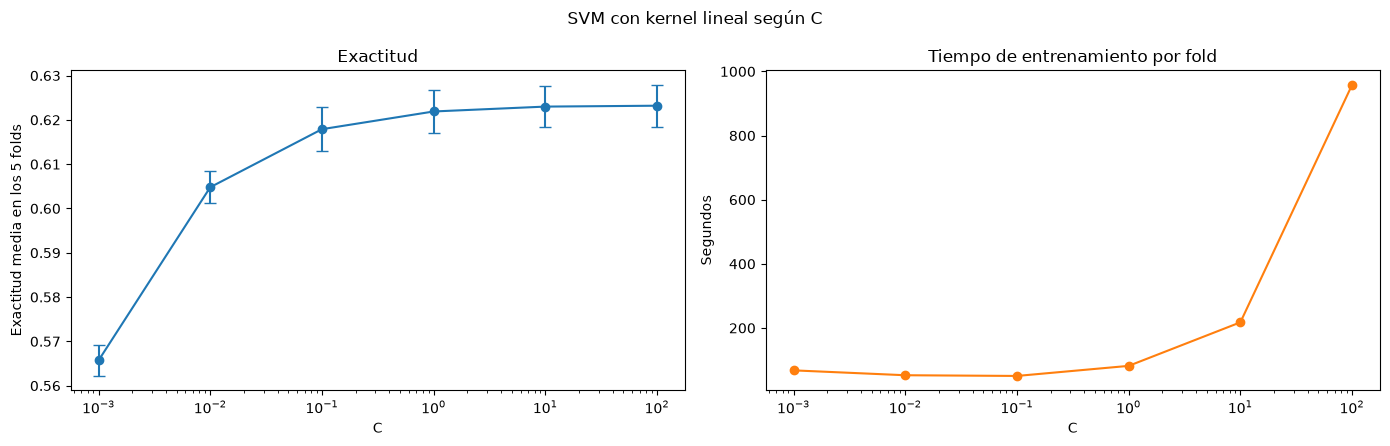

In [19]:
# Exactitud media con el desvío entre folds como barra de error, y tiempo de entrenamiento, según C
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].errorbar(tabla_lineal["C"], tabla_lineal["Exactitud media"], yerr=tabla_lineal["Exactitud desvío"],
                 marker="o", capsize=4)
axes[0].set(xscale="log", xlabel="C", ylabel="Exactitud media en los 5 folds", title="Exactitud")
axes[1].plot(tabla_lineal["C"], tabla_lineal["Entrenamiento por fold (s)"], marker="o", color="tab:orange")
axes[1].set(xscale="log", xlabel="C", ylabel="Segundos", title="Tiempo de entrenamiento por fold")
fig.suptitle("SVM con kernel lineal según C")
plt.tight_layout()
plt.show()

Se cumple. La exactitud sube de 0,5657 con C = 0,001 a 0,6219 con C = 1, y desde ahí casi no cambia (0,6232 con C = 100), con diferencias menores que el desvío entre folds. El tiempo, en cambio, se dispara: de 82 segundos por fold con C = 1 a 958 con C = 100. Con un C grande el modelo intenta no clasificar mal ningún dato, y como los cultivos se superponen, ningún hiperplano lo logra.

Lo que no esperábamos es que se estanque tan abajo: el lineal acierta 6 de cada 10 filas, porque los hiperplanos no alcanzan para separar 10 cultivos que se superponen.

### 2.2 Mejor configuración

In [20]:
# Combinaciones equivalentes a la mejor, de la más rápida a la más lenta: elegimos la primera
mejor_lineal = mejor_configuracion(resultados_lineal)
tabla_lineal.loc[candidatas(resultados_lineal).index]

,C,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
3,1.0,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,81.8
4,10.0,0.6230,0.0049,0.6230,0.0047,0.6230,0.0047,217.6
5,100.0,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,958.1


Elegimos **C = 1**. La mejor exactitud media es la de C = 100 (0,6232, con un desvío de 0,0047), así que el límite es 0,6185 y quedan C = 1, 10 y 100 (C = 0,1 queda afuera por poco, con 0,6179). C = 1 es el más rápido de los tres y pierde solo 0,0013 de exactitud.

---
## 3. SVM con kernel gaussiano (RBF)

### 3.1 Búsqueda de C y gamma

Esperamos que el RBF supere al lineal, porque puede armar fronteras curvas, que el mejor gamma esté en valores intermedios y que el mejor C dependa de gamma.

Probamos 5 valores de C (de 0,1 a 1000) y 5 de gamma (de 0,001 a 10): los 4 de la consigna para cada uno, más C = 1000 y gamma = 10, para que el máximo no quede en un borde de la grilla. Son 125 entrenamientos.

In [21]:
GRILLA_RBF = {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": [0.001, 0.01, 0.1, 1, 10]}
resultados_rbf = buscar_hiperparametros(SVC(kernel="rbf", random_state=SEMILLA), GRILLA_RBF)
tabla_rbf = tabla_resultados(resultados_rbf, {"svc__C": "C", "svc__gamma": "gamma"})

# Ordenada de mayor a menor exactitud media
tabla_rbf.sort_values("Exactitud media", ascending=False)

,C,gamma,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
13,10.0,1.000,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,97.2
17,100.0,0.100,0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,39.4
8,1.0,1.000,0.8834,0.0029,0.8812,0.0029,0.8812,0.0029,93.2
18,100.0,1.000,0.8826,0.0023,0.8805,0.0027,0.8805,0.0027,92.4
23,1000.0,1.000,0.8804,0.0025,0.8783,0.0028,0.8783,0.0028,91.9
22,1000.0,0.100,0.8731,0.0029,0.8736,0.0029,0.8736,0.0029,63.6
12,10.0,0.100,0.8678,0.0038,0.8688,0.0038,0.8688,0.0038,29.9
21,1000.0,0.010,0.8436,0.0023,0.8446,0.0023,0.8446,0.0023,93.8
7,1.0,0.100,0.8239,0.0032,0.8244,0.0034,0.8244,0.0034,28.6
16,100.0,0.010,0.8054,0.0039,0.8061,0.0039,0.8061,0.0039,45.6


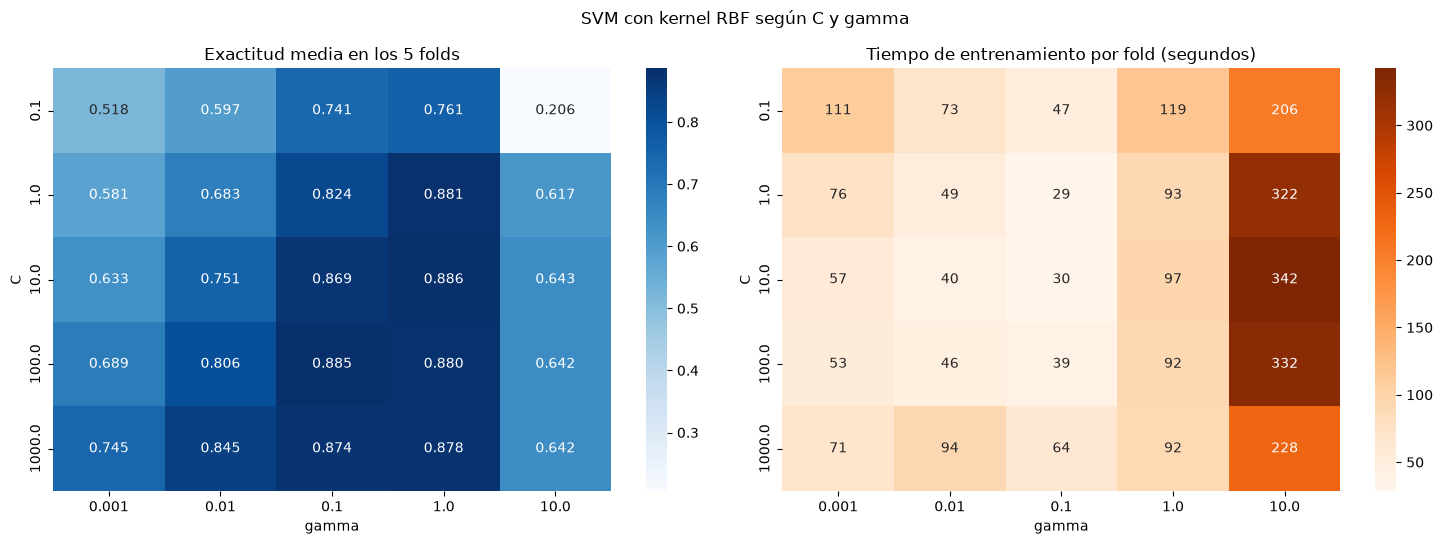

In [22]:
# Exactitud media y tiempo de entrenamiento de cada par de valores de los dos hiperparámetros, con el heatmap de
# seaborn que usamos para las correlaciones. sort=False mantiene el orden de la grilla en filas y columnas
def graficar_interaccion(tabla, filas, columnas, titulo):
    """Mapas de calor de la exactitud media y del tiempo de entrenamiento por fold de cada combinación."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    exactitud = tabla.pivot_table(index=filas, columns=columnas, values="Exactitud media", sort=False)
    sns.heatmap(exactitud, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
    axes[0].set_title("Exactitud media en los 5 folds")
    tiempo = tabla.pivot_table(index=filas, columns=columnas, values="Entrenamiento por fold (s)", sort=False)
    sns.heatmap(tiempo, annot=True, fmt=".0f", cmap="Oranges", ax=axes[1])
    axes[1].set_title("Tiempo de entrenamiento por fold (segundos)")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


graficar_interaccion(tabla_rbf, "C", "gamma", "SVM con kernel RBF según C y gamma")

Se cumple. El RBF llega a 0,886 de exactitud, contra 0,623 del lineal, y cae en los dos extremos de gamma: no pasa de 0,745 con gamma = 0,001 y se derrumba con gamma = 10. Las mejores combinaciones forman una diagonal: con gamma = 0,01 el mejor C es 1000, con 0,1 es 100 y con 1 es 10. Cuanto mayor es gamma, más flexible es la frontera y menos C necesita. El máximo queda dentro de la grilla.

Con gamma = 10 la precisión se separa de la exactitud (con C = 1, 0,8775 contra 0,6172): casi todo lo que predice está bien, pero los errores se juntan en unos pocos cultivos que predice de más. Con un gamma tan grande cada fila influye solo en su entorno inmediato, así que la frontera se ajusta a las filas de entrenamiento sin generalizar. Eso también explica que sean las combinaciones más lentas (de 206 a 342 segundos por fold): casi todas las filas terminan como vectores soporte.

### 3.2 Mejor configuración

In [23]:
# Combinaciones equivalentes a la mejor, de la más rápida a la más lenta: elegimos la primera
mejor_rbf = mejor_configuracion(resultados_rbf)
tabla_rbf.loc[candidatas(resultados_rbf).index]

,C,gamma,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
17,100.0,0.1,0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,39.4
13,10.0,1.0,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,97.2


Elegimos **C = 100 y gamma = 0,1**. La mejor es C = 10 y gamma = 1 (0,8864, con un desvío de 0,0035), así que el límite es 0,8829, y la única otra combinación que lo supera es C = 100 y gamma = 0,1 (0,8850). Es la más rápida de las dos y, además, la que menos varía entre folds de toda la grilla (desvío de 0,0018).

---
## 4. Random Forest

### 4.1 Búsqueda de n_estimators y max_depth

En 1.4, varios grupos de cultivos se separaban con un corte en una sola variable (la temperatura o el pH), que es lo que hace cada nodo de un árbol: esperamos que el Random Forest supere a los dos SVM. También esperamos que la profundidad pese más que la cantidad de árboles (con 5 niveles hay a lo sumo 32 hojas para 10 cultivos) y que sumar árboles mejore cada vez menos mientras el tiempo crece en proporción.

Probamos 5 valores de `n_estimators` (de 50 a 500) y 7 de `max_depth` (de 5 a 30 de 5 en 5, y sin límite): 175 entrenamientos. A las profundidades de la consigna les sumamos 15, 25 y 30, para ver dónde se estabiliza la exactitud. Usamos el mismo pipeline que en los SVM, aunque el Random Forest no necesita datos estandarizados: estandarizar no cambia qué filas quedan de cada lado de un corte.

In [24]:
GRILLA_RF = {"randomforestclassifier__n_estimators": [50, 100, 200, 300, 500],
             "randomforestclassifier__max_depth": [5, 10, 15, 20, 25, 30, None]}
resultados_rf = buscar_hiperparametros(RandomForestClassifier(random_state=SEMILLA), GRILLA_RF)
tabla_rf = tabla_resultados(resultados_rf, {"randomforestclassifier__n_estimators": "n_estimators",
                                            "randomforestclassifier__max_depth": "max_depth"})
# max_depth=None es sin límite de profundidad
tabla_rf["max_depth"] = tabla_rf["max_depth"].fillna("sin límite")

# Ordenada de mayor a menor exactitud media
tabla_rf.sort_values("Exactitud media", ascending=False)

,n_estimators,max_depth,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
29,500,30,0.9162,0.0034,0.9167,0.0034,0.9167,0.0034,89.6
34,500,sin límite,0.9162,0.0035,0.9167,0.0036,0.9167,0.0036,72.4
33,300,sin límite,0.9158,0.0034,0.9164,0.0034,0.9164,0.0034,50.1
28,300,30,0.9157,0.0035,0.9162,0.0035,0.9162,0.0035,54.0
24,500,25,0.9153,0.0036,0.9158,0.0036,0.9158,0.0036,89.0
23,300,25,0.9150,0.0030,0.9156,0.0030,0.9156,0.0030,53.3
32,200,sin límite,0.9150,0.0037,0.9155,0.0037,0.9155,0.0037,36.5
27,200,30,0.9146,0.0034,0.9152,0.0034,0.9152,0.0034,35.8
22,200,25,0.9147,0.0034,0.9152,0.0034,0.9152,0.0034,36.2
31,100,sin límite,0.9143,0.0030,0.9149,0.0031,0.9149,0.0031,17.9


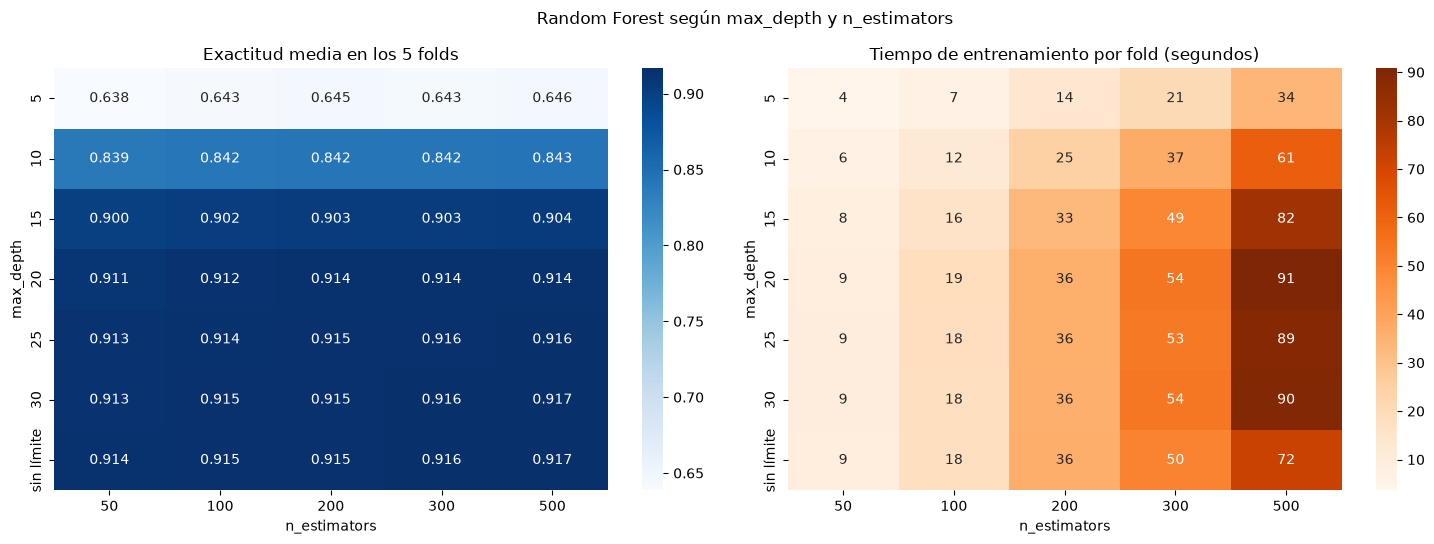

In [25]:
graficar_interaccion(tabla_rf, "max_depth", "n_estimators", "Random Forest según max_depth y n_estimators")

Se cumple. La profundidad es lo que más cambia la exactitud: con `max_depth = 5` no pasa de 0,646, con 15 llega a 0,904 y desde 25 se estabiliza entre 0,913 y 0,917. Pasar de 50 a 500 árboles mejora menos de 0,01, mientras el tiempo crece en proporción (sin límite de profundidad, de 9 a 72 segundos por fold). Desde `max_depth = 15`, todas las combinaciones superan a la mejor del RBF (0,8864).

Los tiempos tienen algo de ruido, porque se midieron con varios modelos entrenándose a la vez: con 500 árboles, `max_depth = 30` tarda más que sin límite (90 y 72 segundos), cuando limitar la profundidad solo puede ahorrar trabajo.

### 4.2 Mejor configuración

In [26]:
# Combinaciones equivalentes a la mejor, de la más rápida a la más lenta: elegimos la primera
mejor_rf = mejor_configuracion(resultados_rf)
tabla_rf.loc[candidatas(resultados_rf).index]

,n_estimators,max_depth,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
30,50,sin límite,0.9130,0.0036,0.9137,0.0036,0.9137,0.0036,8.9
31,100,sin límite,0.9143,0.0030,0.9149,0.0031,0.9149,0.0031,17.9
26,100,30,0.9143,0.0031,0.9149,0.0031,0.9149,0.0031,18.2
21,100,25,0.9140,0.0032,0.9145,0.0032,0.9145,0.0032,18.4
27,200,30,0.9146,0.0034,0.9152,0.0034,0.9152,0.0034,35.8
22,200,25,0.9147,0.0034,0.9152,0.0034,0.9152,0.0034,36.2
17,200,20,0.9134,0.0034,0.9138,0.0035,0.9138,0.0035,36.3
32,200,sin límite,0.9150,0.0037,0.9155,0.0037,0.9155,0.0037,36.5
33,300,sin límite,0.9158,0.0034,0.9164,0.0034,0.9164,0.0034,50.1
23,300,25,0.9150,0.0030,0.9156,0.0030,0.9156,0.0030,53.3


Elegimos **50 árboles sin límite de profundidad**. La mejor es 500 árboles con `max_depth = 30` (0,9167, con un desvío de 0,0034), así que el límite es 0,9133. Lo superan 16 combinaciones, todas con `max_depth` de 20 en adelante, y la más rápida es la de 50 árboles sin límite (0,9137). Queda cerca del límite: con `max_depth = 30`, 50 árboles (0,9131) ya quedan afuera.

### 4.3 Importancia de las variables

Analizamos la importancia del bosque elegido, entrenado con todos los datos limpios. Por 1.4, esperamos que las más importantes sean las temperaturas y el pH, y que `temperatura` y `temp_min_mensual`, muy correlacionadas (0,95, en 1.7), se repartan la importancia.

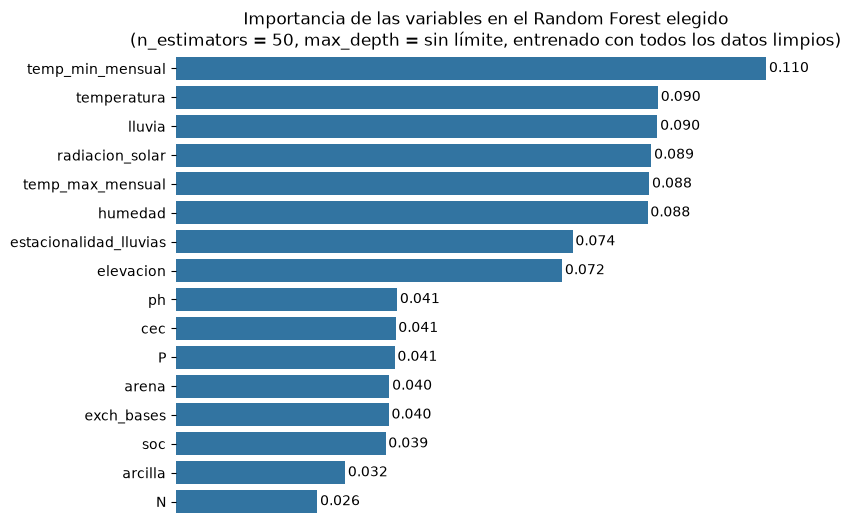

In [27]:
# El bosque con la configuración elegida, reentrenado con los 49803 datos limpios (los 5 folds juntos). n_jobs=-1
# entrena los árboles en paralelo y no cambia el resultado
bosque = crear_modelo(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)).set_params(**mejor_rf["params"])
bosque.fit(X, y)

# Importancia de cada variable, con el gráfico de barras de Ensambles_RandomForest.ipynb (U6, sección "Importancia
# de las características"). bosque[-1] es el último paso del pipeline, el Random Forest
importancias = pd.DataFrame({"variable": ATRIBUTOS, "importancia": bosque[-1].feature_importances_})
importancias = importancias.sort_values(by="importancia", ascending=False)

plt.figure(figsize=(8, 6))
g = sns.barplot(data=importancias, x="importancia", y="variable")
sns.despine(bottom=True, left=True)
g.set_title(f"Importancia de las variables en el Random Forest elegido\n(n_estimators = "
            f"{tabla_rf.loc[mejor_rf.name, 'n_estimators']}, max_depth = {tabla_rf.loc[mejor_rf.name, 'max_depth']}, "
            "entrenado con todos los datos limpios)")
g.set(xlabel=None, ylabel=None, xticks=[])
for barras in g.containers:
    g.bar_label(barras, padding=2, fmt="%.3f")
plt.show()

Se cumple en parte. Las ocho primeras son de clima o ubicación (de 0,072 a 0,110) y las ocho del suelo quedan abajo (de 0,026 a 0,041). El pH es la primera del suelo, pero queda novena: puede ser que la separación entre suelos ácidos y neutros de 1.4 ya la den la humedad y la lluvia, con las que está muy correlacionado (−0,79 y −0,78).

`temp_min_mensual` y `temperatura` son las dos primeras y juntas suman alrededor de 0,2, más del doble que cualquier otra variable. Es coherente con que se repartan los cortes, aunque con este gráfico solo no se puede comprobar.

---
## 5. Comparación de modelos

### 5.1 Métricas de la mejor configuración de cada algoritmo

In [28]:
# La fila de la configuración elegida de cada algoritmo en las tablas de 2, 3 y 4
COLUMNAS = list(tabla_lineal.columns.drop("C"))
comparacion = pd.DataFrame([tabla_lineal.loc[mejor_lineal.name, COLUMNAS],
                            tabla_rbf.loc[mejor_rbf.name, COLUMNAS],
                            tabla_rf.loc[mejor_rf.name, COLUMNAS]],
                           index=["SVM lineal", "SVM RBF", "Random Forest"])
configuracion_rf = tabla_rf.loc[mejor_rf.name]
comparacion.insert(0, "Configuración", [
    f"C = {mejor_lineal['param_svc__C']:g}",
    f"C = {mejor_rbf['param_svc__C']:g}, gamma = {mejor_rbf['param_svc__gamma']:g}",
    f"n_estimators = {configuracion_rf['n_estimators']}, max_depth = {configuracion_rf['max_depth']}"])
comparacion

,Configuración,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
SVM lineal,C = 1,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,81.8
SVM RBF,"C = 100, gamma = 0.1",0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,39.4
Random Forest,"n_estimators = 50, max_depth = sin límite",0.9130,0.0036,0.9137,0.0036,0.9137,0.0036,8.9


El Random Forest es el mejor en las tres métricas: 0,029 de exactitud más que el RBF y 0,29 más que el lineal. La diferencia con el RBF es unas ocho veces el desvío del Random Forest entre folds, así que, a diferencia de las configuraciones dentro de cada modelo, es firme. Los tres son estables (el desvío de la exactitud no pasa de 0,005), y el que menos varía es el RBF.

En tiempo de entrenamiento, el Random Forest es el más rápido, seguido por el RBF y el lineal. Como se midieron durante las búsquedas (4.1), los tiempos sirven para comparar los modelos entre sí, pero no son los de un modelo entrenado solo.

### 5.2 Matrices de confusión

Usamos el fold 1 (el de 1.8), una de las opciones de la consigna: cada modelo se entrena con los otros 4 folds, como en las búsquedas.

Por 1.4, esperamos errores en `banana` y `cafe`, que se parecen en casi todas las variables, y en `maiz`, el de rangos más amplios. También esperamos que se confundan `garbanzo` y `lenteja`: tienen suelos neutros y poca lluvia, y `garbanzo` tiene una cola de temperaturas bajas que llega a las de `lenteja`.

In [29]:
# Primer fold de la validación cruzada (el mismo de 1.8): cada modelo se entrena con los otros 4 folds y predice este
X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
y_train, y_test = y[indices_train], y[indices_test]

# La configuración elegida de cada algoritmo
modelos = {"SVM lineal": crear_modelo(SVC(kernel="linear", random_state=SEMILLA)).set_params(**mejor_lineal["params"]),
           "SVM RBF": crear_modelo(SVC(kernel="rbf", random_state=SEMILLA)).set_params(**mejor_rbf["params"]),
           "Random Forest": crear_modelo(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)).set_params(
               **mejor_rf["params"])}

# Entrenamos cada modelo con los 4 folds de entrenamiento y guardamos sus predicciones sobre el fold 1
predicciones = pd.DataFrame()
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)

for nombre in predicciones:
    print(f"{nombre}: exactitud {accuracy_score(y_test, predicciones[nombre]):.4f} en el fold 1")

SVM lineal: exactitud 0.6188 en el fold 1
SVM RBF: exactitud 0.8851 en el fold 1
Random Forest: exactitud 0.9109 en el fold 1


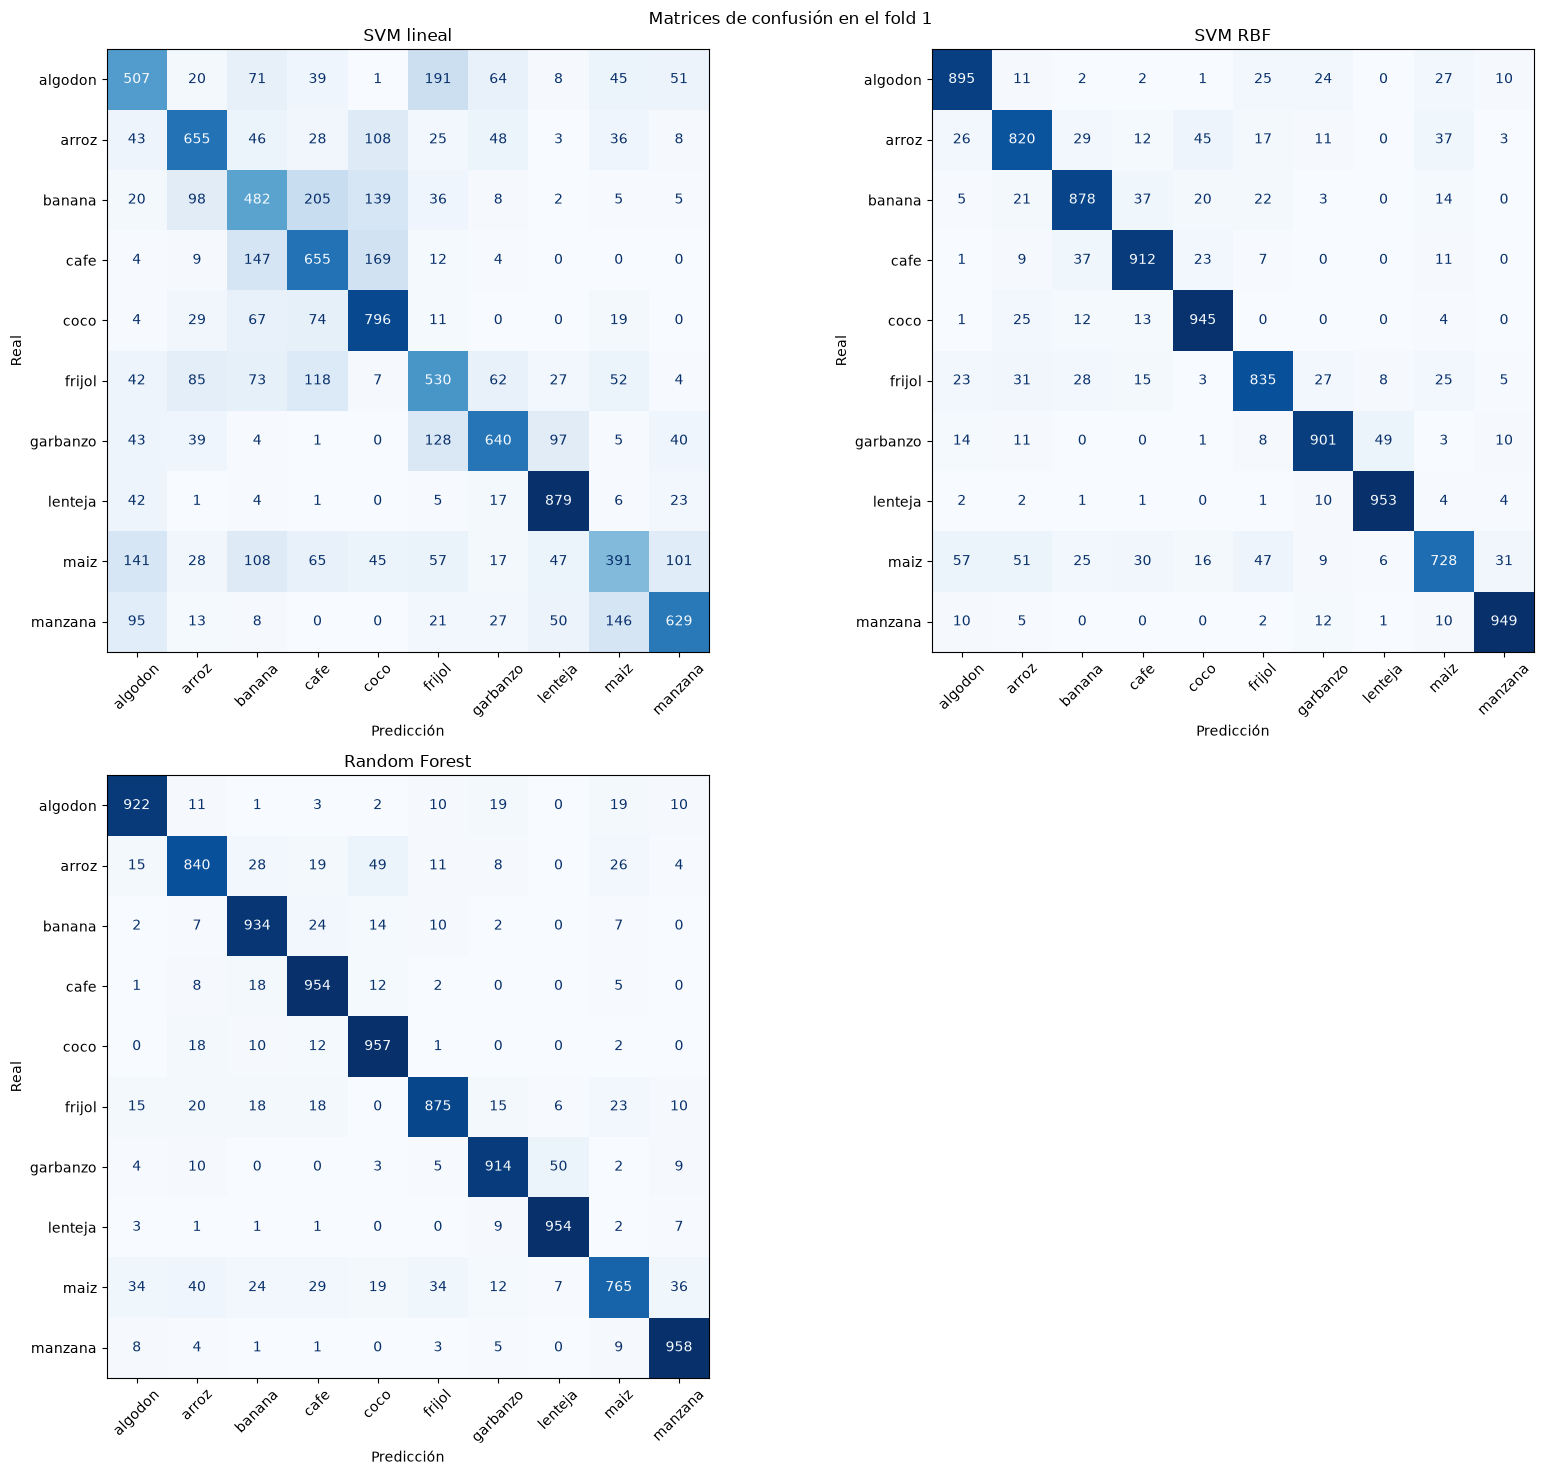

In [30]:
# Adaptado de plot_multiple_conf_matrices de gas_detection.ipynb (U6): la misma grilla de 2 × 2 con una matriz por
# modelo, pero con ConfusionMatrixDisplay (como en el TP2), el mismo mapa de colores para las tres y los nombres de
# los cultivos en los ejes
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
axes = axes.flatten()
for ax, nombre in zip(axes, predicciones):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=codificador.classes_,
                                            cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Real")
fig.delaxes(axes[3])   # sobra el cuarto lugar de la grilla
fig.suptitle("Matrices de confusión en el fold 1")
plt.tight_layout()
plt.show()

Las exactitudes en el fold 1 (0,6188, 0,8851 y 0,9109) están cerca de las medias de 5.1, así que el fold es representativo.

Se cumple en parte. `maiz` es el cultivo que más les cuesta a los tres (de sus 1000 filas, el Random Forest acierta 765, el RBF 728 y el lineal 391), con errores repartidos entre todos los demás, y `garbanzo` clasificado como `lenteja` es el error más frecuente del Random Forest (50 filas; 49 en el RBF). En cambio, `banana` y `cafe` solo se confunden mucho en el lineal (205 filas en un sentido y 147 en el otro): los modelos no lineales encuentran combinaciones de variables que las separan. Un error que no anticipamos es `arroz` clasificado como `coco` (45 filas en el RBF y 49 en el Random Forest): en 1.4 son los dos cultivos de menor elevación y están entre los más cálidos.

### 5.3 Elección del modelo

Elegimos **el Random Forest, con 50 árboles sin límite de profundidad**.

En las métricas es el mejor, con una diferencia firme sobre el RBF. En estabilidad, el RBF varía menos entre folds (desvío de 0,0018 contra 0,0036), pero las dos variaciones son chicas al lado de esa diferencia. En interpretabilidad, un bosque de 50 árboles no se puede seguir como un árbol, pero es el único de los tres que muestra en qué variables se apoya (4.3): sobre todo, en el clima. El SVM lineal tiene un vector de coeficientes por cada par de cultivos, porque scikit-learn entrena un clasificador para cada par, y el RBF no da esa información. En tiempo de entrenamiento, también es el más rápido.

El SVM lineal queda descartado por su exactitud. El RBF es la alternativa más cercana y la más estable, pero clasifica peor, tarda más y no muestra en qué se basa.

---
## 6. Conclusiones

1. El conjunto tenía una fila con faltantes, 198 filas duplicadas y 2 filas con valores imposibles, y las eliminamos. Los miles de atípicos que marca la regla del rango intercuartílico se concentran en pocos cultivos y son valores posibles, así que los conservamos.
2. El SVM lineal no alcanza para este problema: se estanca en 0,62 de exactitud, y subir C solo multiplica el tiempo de entrenamiento.
3. El SVM RBF llega a 0,886 de exactitud. El mejor C depende de gamma, y con gamma = 10 el modelo se derrumba. Elegimos C = 100 y gamma = 0,1 (0,885), que rinde lo mismo que la mejor, entrena más rápido y varía menos entre folds.
4. El Random Forest es el mejor modelo: con 50 árboles sin límite de profundidad llega a 0,914 de exactitud. La profundidad pesa mucho más que la cantidad de árboles, y las variables de clima más que las del suelo.
5. Dentro de cada modelo, varias configuraciones quedan a menos de un desvío de la mejor, y elegir la más rápida nos costó como mucho 0,003 de exactitud. Entre modelos, en cambio, las diferencias son claras.
6. Elegimos el Random Forest por su exactitud, su tiempo de entrenamiento y porque muestra en qué variables se apoya. Sus errores están en parte donde los anticipó el análisis exploratorio: en `maiz` y entre `garbanzo` y `lenteja`.